# Insurance Customer Analytics and Personal Data Obfuscation

**`Case study | Data analysis, machine learning, and linear algebra`**

## 1. Business Context and Problem Statement

The insurance company Protect Your Tomorrow (Proteja Seu Amanhã) wants to investigate how data analysis and machine learning can help it understand customer profiles and analyze their histories of insurance benefit payments.

The company has a dataset containing policyholders’ personal characteristics and the number of insurance benefit payments each customer received over the preceding five years.

Using these data, the study will assess whether the company can identify customers with similar profiles, classify customers according to their payment histories, and estimate the number of payments associated with each profile.

At the same time, the company wants to investigate ways to make personal information harder to interpret directly without compromising the predictive performance of its regression models.

The project therefore combines four related analytical problems: customer similarity, classification, regression, and data transformation.

### 1.1 Objectives and Business Questions

The main objective of this study is to assess the potential of several machine learning and linear algebra techniques to answer the following questions:

1. **How can we identify customers with similar profiles?**

Finding similar customers could support segmentation analyses and marketing initiatives. We will investigate nearest-neighbor search methods, comparing distance metrics and the effect of feature scaling.

2. **Can we identify customers with a history of receiving insurance benefit payments?**

We will evaluate whether a classification model can distinguish customers who received at least one insurance benefit payment from those who received none during the observed period. We will compare its performance with baseline models to determine whether it offers a predictive improvement.

3. **Can we estimate the number of insurance benefit payments a customer has received?**

We will implement a linear regression model to estimate the number of payments from the available characteristics. The experiment will also examine how feature scaling affects the model's results.

4. **Can we obfuscate personal information without degrading linear regression performance?**

We will investigate a transformation that multiplies the data by an invertible matrix. The goal is to demonstrate, using a mathematical proof and computational tests, the conditions under which this transformation preserves linear regression predictions.

### 1.2 Available Data

The dataset contains **5,000 policyholder records**, with the following variables:

| Variable | Description |
|---|---|
| `gender` | Policyholder's sex, numerically encoded |
| `age` | Policyholder's age |
| `income` | Policyholder's income |
| `family_members` | Number of family members |
| `insurance_benefits` | Number of insurance benefit payments received during the preceding five years |

The first four variables will serve as predictive features. The `insurance_benefits` variable will provide the targets for the classification and regression experiments.

### 1.3 Analytical Approach

The study consists of four experiments, preceded by data preparation and exploratory data analysis.

We will use nearest-neighbor search, k-nearest neighbors (kNN) classification, linear regression, and matrix operations with NumPy.

In addition to evaluating predictive performance, the project aims to understand the algorithms' mathematical behavior and the effects of transformations applied to the data.

**Scope and limitations:** The recorded insurance benefit payments describe a five-year history, not future outcomes observed after a prediction is made. Therefore, these experiments evaluate the ability to recognize patterns in historical records; they do not, on their own, establish an ability to forecast future payments in an operational setting.

Likewise, the matrix transformation explored in the obfuscation experiment is not an encryption method and does not guarantee protection against attacks. Its purpose is to demonstrate mathematical properties relevant to feature transformations and the preservation of linear regression predictions.

## 2. Data Preparation and Exploratory Data Analysis

Before developing machine learning models, we need to understand the structure and characteristics of the dataset.

This stage aims to assess data quality, identify potential inconsistencies, and understand the distributions of the variables used in the subsequent experiments.

We will also examine differences in feature scales and the distribution of insurance benefit payments, as both can directly affect the behavior of the algorithms used later.

### 2.1 Data Loading and Initial Inspection

We will begin by importing the required libraries and loading the dataset.

After loading, we will inspect the table's shape, data types, and a sample of its records. Column names will also be standardized to make them easier to use throughout the project.

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.linear_model
import sklearn.metrics
import sklearn.neighbors
import sklearn.preprocessing
from IPython.display import display
from matplotlib import pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

In [2]:
Path("../assets/figures/").mkdir(exist_ok=True,parents=True)

In [3]:
filename = 'insurance_us.csv'

data_dir = next(
    (
        path for path in [Path("../data"), Path("../datasets"), Path("/datasets/")]
        if (path / filename).is_file()
    ),
    None,
)

if data_dir is None:
    raise FileNotFoundError("File not found. Place insurance_us.csv in ../data/, ../datasets/, or /datasets/.")

df_raw = pd.read_csv(data_dir / filename)
df = df_raw.copy()

#### Original Dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              5000 non-null   int64  
 1   Age                 5000 non-null   float64
 2   Salary              5000 non-null   float64
 3   Family members      5000 non-null   int64  
 4   Insurance benefits  5000 non-null   int64  
dtypes: float64(2), int64(3)
memory usage: 195.4 KB


In [5]:
# Helper functions

def snake_case_columns(df:pd.DataFrame):
    '''Converts a pandas DataFrame's column names to snake_case.'''
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

In [6]:
# Convert column names to snake_case and rename 'salary' to 'income'
df = snake_case_columns(df).rename(columns={'salary':'income'})
# Convert 'age' to integer
assert (df["age"] % 1 == 0).all(), (
    "The age column contains non-integer values."
)

df["age"] = df["age"].astype(int)


#### Standardized Dataset (snake_case, Data Types, and Names)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   gender              5000 non-null   int64  
 1   age                 5000 non-null   int64  
 2   income              5000 non-null   float64
 3   family_members      5000 non-null   int64  
 4   insurance_benefits  5000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 195.4 KB


In [8]:
data_quality = pd.DataFrame({
    "File name": [filename],
    "DataFrame shape": [df.shape],
    "Row count": [df.shape[0]],
    "Column count": [df.shape[1]],
    "Missing values": df.isnull().sum().sum(),
    "Rows belonging to duplicate groups": df.duplicated(keep=False).sum(),
    "Duplicate rows (excluding first occurrences)": df.duplicated().sum(),
})

display(data_quality)

,File name,DataFrame shape,Row count,Column count,Missing values,Rows belonging to duplicate groups,Duplicate rows (excluding first occurrences)
0,insurance_us.csv,"(5000, 5)",5000,5,0,300,153


In [9]:
print("Repeated rows and occurrence counts for each identical record:")
display(df.loc[df.duplicated(keep=False)].groupby(df.columns.tolist()).size().reset_index(name='occurrence_count').sort_values(by='occurrence_count', ascending=False))

Repeated rows and occurrence counts for each identical record:


,gender,age,income,family_members,insurance_benefits,occurrence_count
76,1,19,43200.0,1,0,3
115,1,30,49900.0,1,0,3
6,0,21,37200.0,0,0,3
33,0,28,39800.0,1,0,3
45,0,31,49400.0,1,0,3
...,...,...,...,...,...,...
52,0,33,33700.0,2,0,2
53,0,33,41500.0,1,0,2
54,0,33,59300.0,2,0,2
55,0,34,39900.0,0,0,2


The `insurance_us` dataset contains 5,000 policyholder records and five columns:

- `gender` — customer's encoded sex
- `age` — customer's age
- `income` — customer's income
- `family_members` — number of family members
- `insurance_benefits` — number of insurance benefit payments received (**machine learning target**)

There appear to be no missing or null values.

There are 153 duplicate rows beyond their first occurrences. These are part of the 300 rows that share all their values with at least one other row. There are no unique customer identifiers, so it is impossible to determine whether these repeated records correspond to different customers or duplicate entries for the same customers. Because distinct customers can legitimately share identical characteristics, there is insufficient evidence to discard these records.

### 2.2 Data Quality and Characteristics

Here, we will examine descriptive statistics, including measures of central tendency, dispersion, and range.

We will also look for missing values, inconsistent data types, and potentially atypical observations.

It is important to distinguish statistical outliers from incorrect records. An observation far from most of the distribution is not necessarily an error and may contain information relevant to the models.

In [10]:
df.describe()

,gender,age,income,family_members,insurance_benefits
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.499000,30.952800,39916.360000,1.194200,0.148000
std,0.500049,8.440807,9900.083569,1.091387,0.463183
min,0.000000,18.000000,5300.000000,0.000000,0.000000
25%,0.000000,24.000000,33300.000000,0.000000,0.000000
50%,0.000000,30.000000,40200.000000,1.000000,0.000000
75%,1.000000,37.000000,46600.000000,2.000000,0.000000
max,1.000000,65.000000,79000.000000,6.000000,5.000000


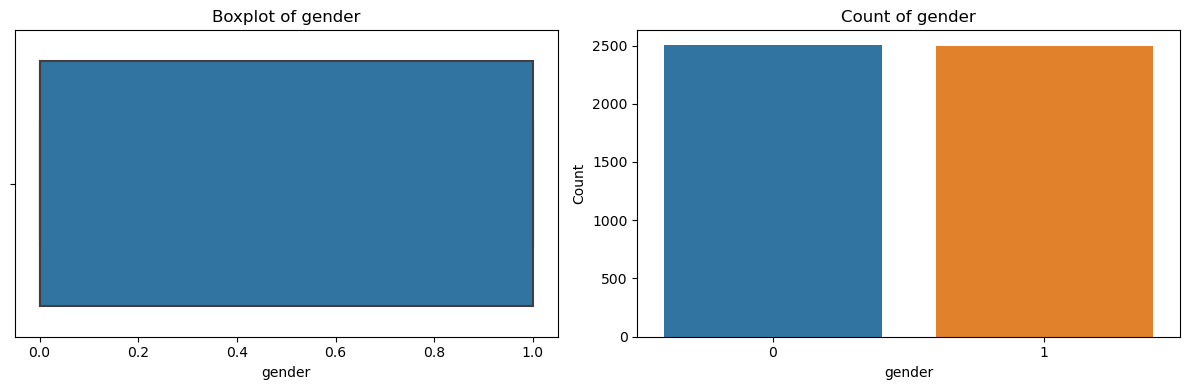

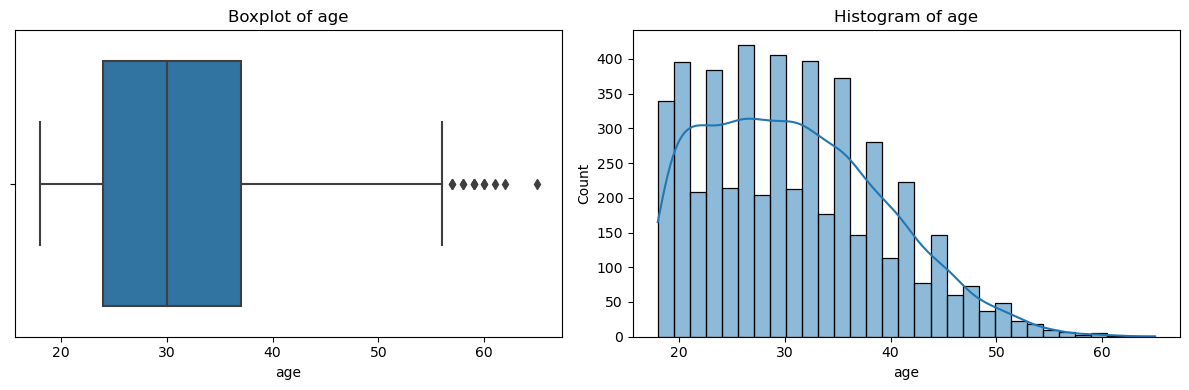

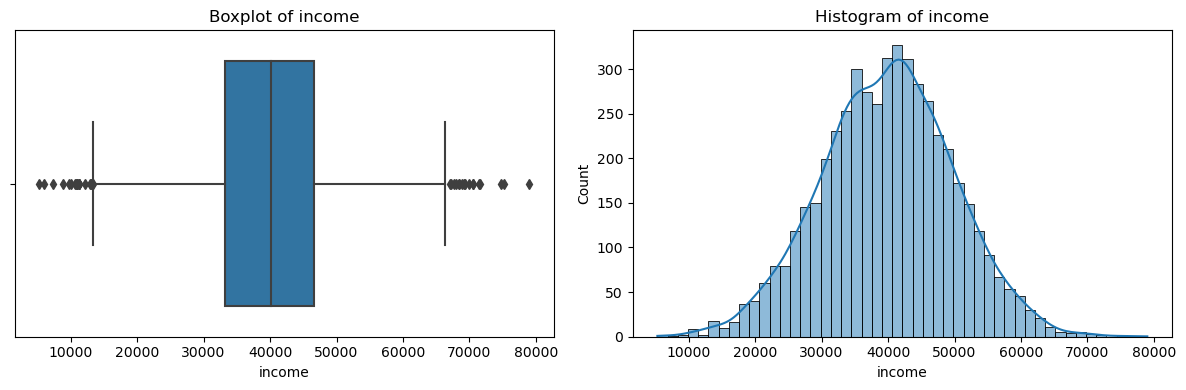

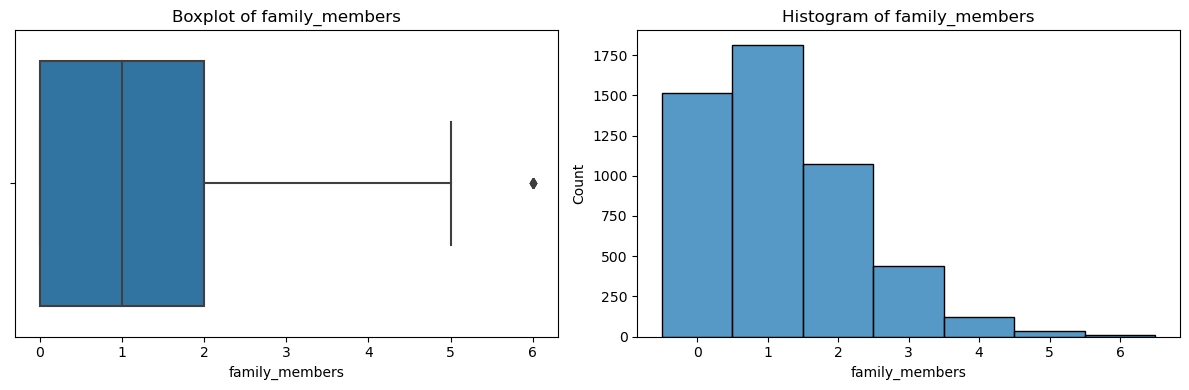

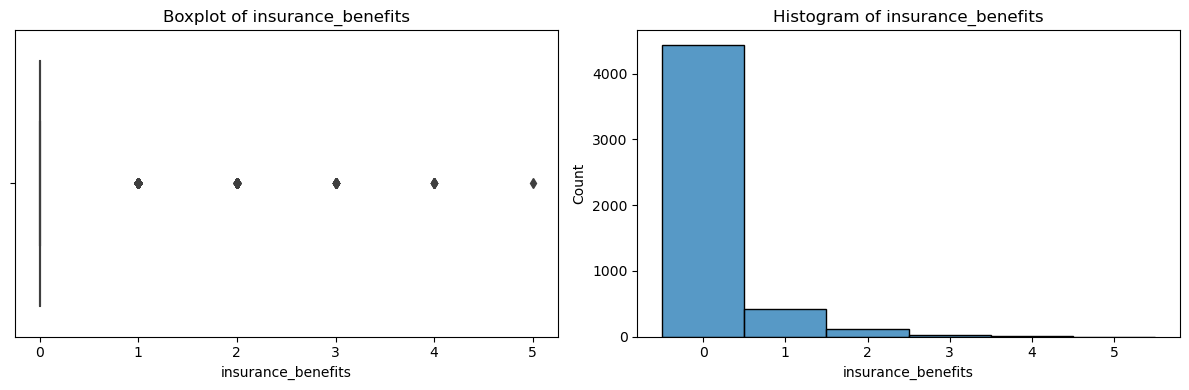

In [11]:
continuous_columns = ['age', 'income']
discrete_columns = ['family_members','insurance_benefits']

for col in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(data=df, x=col, ax=axes[0])
    axes[0].set_title(f"Boxplot of {col}")

    if col == 'gender':
        sns.countplot(data=df, x=col, ax=axes[1])
        axes[1].set_title(f'Count of {col}')
        axes[1].set_ylabel('Count')
    else:
        sns.histplot(data=df, x=col,kde=col in continuous_columns, discrete=col in discrete_columns, ax=axes[1],stat='count')
        axes[1].set_title(f'Histogram of {col}')
        axes[1].set_ylabel('Count')

    plt.tight_layout()
    plt.show()
    plt.close(fig)


Boxplots identify statistically atypical observations using the $1.5 	imes IQR$ (interquartile range) criterion. Values classified as outliers under this rule appear as individual diamond markers in the plots above. Note that the ends of the whiskers do not necessarily coincide with the numerical outlier fences: they extend to actual observations that still fall within the allowed range.

`gender`: The distribution is almost perfectly balanced between the two encoded values, 0 and 1. Its mean of 0.4990 indicates that approximately 50% of the records belong to each category. The dataset does not clearly specify which code corresponds to which sex.

`age`: The median age is 30 years, and the interquartile range runs from 24 to 37. Half of the customers therefore fall within this age interval. The distribution has a right tail, with fewer customers at older ages.

`income`: The median income is 40,200, with an interquartile range from 33,300 to 46,600. Some observations lie relatively far from this central interval, including values flagged by the $1.5 	imes IQR$ rule. The smaller representation of extreme income levels may be relevant when evaluating model performance for those segments.

`family_members`: Half of the customers have between zero and two family members, while many others have up to five. Customers with six family members are very rare, and no records have more than six.

`insurance_benefits`: This variable is heavily concentrated at zero, indicating that most customers received no insurance benefit payments during the observed period. Because Q1, Q2, and Q3 are all zero, the IQR is also zero; consequently, every positive value is flagged as an outlier by the boxplot rule. Here, this reflects the skewed distribution of payments rather than necessarily indicating incorrect records. It also suggests class imbalance in the classification task.

Overall, the variables have distinct distributional characteristics. `gender` is nearly balanced between its two categories, whereas age and income are more concentrated around their central values. Lower family-member counts are more common, and the number of insurance benefit payments is strongly concentrated at zero.

Statistical outliers were identified, particularly toward the extremes of the age, income, and family-size distributions. We will retain these records because there is no evidence that they are incorrect.

Differences in feature scale must be considered when using distance-based methods. The low prevalence of positive payment counts also warrants attention when evaluating the classification and regression models.

### 2.3 Exploratory Data Analysis

After the initial inspection, we will investigate the distributions of policyholder characteristics and their possible relationships with the number of insurance benefit payments.

This analysis will help identify preliminary patterns and formulate hypotheses for further investigation.

Of particular interest are the distribution of payment counts and the differences in feature scales, as these can affect classification evaluation and the distance calculations used by kNN, respectively.

To complement the individual distribution analyses, we will examine relationships between pairs of variables. The goal is to identify patterns of association, concentrations of observations, and possible differences between customer profiles according to their histories of insurance benefit payments.

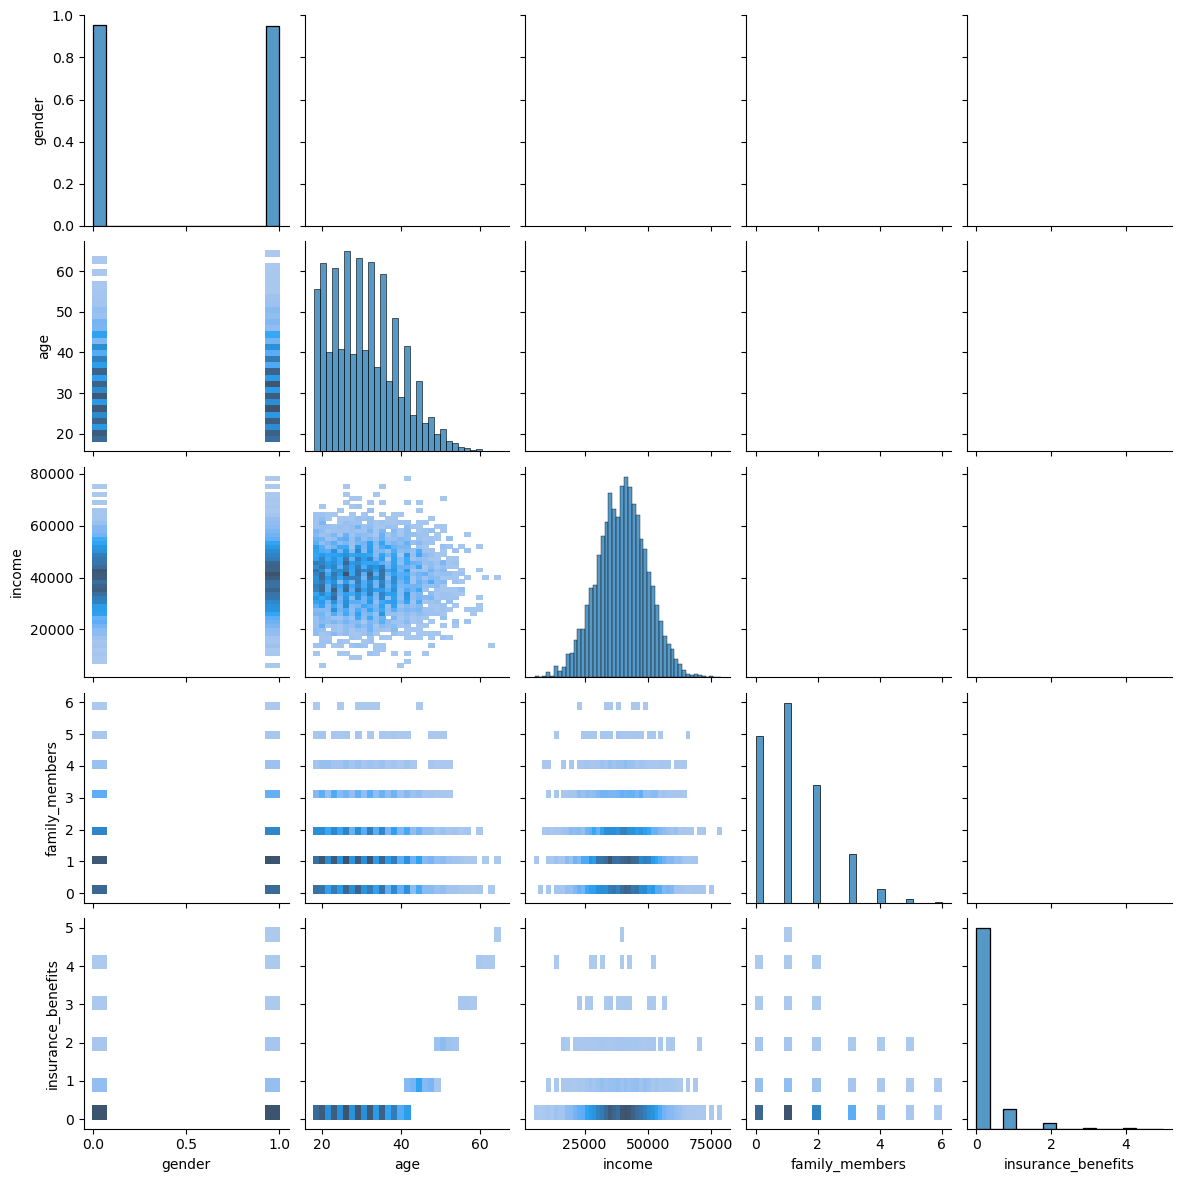

In [12]:
g = sns.PairGrid(df, diag_sharey=False)
g.map_diag(sns.histplot)
g.map_lower(sns.histplot)
g.fig.set_size_inches(12, 12)
g.tight_layout()

In [13]:
age_summary = df.groupby("age").agg(
    client_count=("insurance_benefits", "size"),
    clients_with_benefits=(
        "insurance_benefits",
        lambda s: (s > 0).sum()
    ),
    benefits_rate=(
        "insurance_benefits",
        lambda s: (s > 0).mean()
    )
)
print("Summary of payment rates by age:")
display(age_summary.sort_values(by='benefits_rate',ascending=False).round(4))

Summary of payment rates by age:


,client_count,clients_with_benefits,benefits_rate
age,,,
65,1,1,1.0000
52,22,22,1.0000
43,77,77,1.0000
44,74,74,1.0000
45,73,73,1.0000
46,60,60,1.0000
47,47,47,1.0000
48,26,26,1.0000
49,37,37,1.0000


The pairwise analysis did not reveal clearly separated clusters. However, it did reveal a particularly strong association between customer age and receipt of insurance benefit payments.

The quantitative analysis confirms that no customer younger than 42 received a payment during the observed period. Among customers aged 42, approximately 60.22% received at least one payment. All customers older than 42 have at least one recorded payment.

This pattern suggests that age may have substantial discriminative power in the classification task. The abrupt transition also deserves attention, as it could reflect particularities of how the dataset was constructed or selected rather than a relationship that generalizes to other populations.

It is worth noting that the number of customers declines at older ages. Therefore, rates of 100% based on very small groups should be interpreted cautiously.

In the following sections, we will investigate how this association is reflected in predictive model performance.

## 3. Customer Similarity Analysis

### 3.1 Objective and Methodology

One of the insurance company's needs is to find customers whose characteristics resemble those of a particular policyholder.

This analysis could provide a starting point for segmentation and marketing initiatives by identifying customers with similar demographic and economic profiles.

To investigate this possibility, we will use a *nearest-neighbor search* algorithm, which identifies the most similar observations according to a distance metric.

We will compare two metrics:

- **Euclidean distance:** the straight-line distance between two points in the feature space.
- **Manhattan distance:** the sum of the absolute coordinate-wise differences between two points.

We will also compare results using features at their original scales and after applying `MaxAbsScaler`.

This comparison matters because the available variables have different numerical magnitudes. Without scaling, features with larger values can have a disproportionate influence on distance calculations.

The number of insurance benefit payments will not be included in the similarity calculation, as the goal is to identify similar customers based on their personal characteristics, regardless of their payment histories.

### 3.2 Feature Scaling

The available features have substantially different numerical scales. While `gender` takes only the values 0 and 1, policyholders' incomes can reach tens of thousands of units.

Because nearest-neighbor algorithms rely on distances between observations, these differences can cause features with larger numerical magnitudes to dominate the calculation, even when they are not necessarily more relevant to the analysis.

To examine this effect, we will use `MaxAbsScaler`, which divides each feature by its largest absolute observed value. As all features in this dataset are nonnegative, their transformed values will lie between 0 and 1.

Scaling reduces differences in magnitude but does not guarantee that all features contribute equally to distance calculations. Binary features, for example, may still exert considerable influence on neighbor selection.

In [14]:
feature_names = ['gender', 'age', 'income', 'family_members']

transformer_mas = sklearn.preprocessing.MaxAbsScaler().fit(df[feature_names].to_numpy())

df_scaled = df.copy()
df_scaled.loc[:, feature_names] = transformer_mas.transform(df[feature_names].to_numpy())

In [15]:
df_scaled.sample(5,random_state=12345)

,gender,age,income,family_members,insurance_benefits
3183,0.0,0.507692,0.493671,0.666667,0
1071,0.0,0.769231,0.545570,0.333333,2
2640,1.0,0.600000,0.532911,0.000000,0
2282,0.0,0.307692,0.440506,0.000000,0
1595,0.0,0.630769,0.506329,0.666667,0


### 3.3 Identifying the Nearest Neighbors

In [16]:
# Function to find the k nearest neighbors of a specific record
# in the DataFrame using the specified distance metric.

# The implementation excludes the query record itself from the
# nearest-neighbor results.

def get_knn(df, n, k, features, metric="euclidean"):
    """
    Returns the k nearest neighbors of the record at position n,
    excluding the query record itself.
    """
    if not 0 <= n < len(df):
        raise IndexError("Invalid record position.")

    if not 1 <= k < len(df):
        raise ValueError("k must be between 1 and len(df) - 1.")

    X = df[features]

    model = sklearn.neighbors.NearestNeighbors(
        n_neighbors=k + 1,
        metric=metric
    ).fit(X)

    distances, indices = model.kneighbors(X.iloc[[n]])

    # Exclude the reference record by position
    mask = indices[0] != n

    neighbor_positions = indices[0][mask][:k]
    neighbor_distances = distances[0][mask][:k]

    result = df.iloc[neighbor_positions].copy()
    result["distance"] = neighbor_distances

    return result

In [17]:
n = 0 # Reference record for comparison: use the first record
k = 10 # Select 10 neighbors for a useful comparison sample

df_neighbors_euclidean = get_knn(df,n,k,feature_names,"euclidean")
df_neighbors_manhattan = get_knn(df,n,k,feature_names,"manhattan")
df_scaled_neighbors_euclidean = get_knn(df_scaled,n,k,feature_names,"euclidean")
df_scaled_neighbors_manhattan = get_knn(df_scaled,n,k,feature_names,"manhattan")

In [18]:
print('10 nearest neighbors of record 0 using Euclidean distance (UNSCALED):')
display(df_neighbors_euclidean)
print('10 nearest neighbors of record 0 using Euclidean distance (SCALED):')
display(df_scaled_neighbors_euclidean)

10 nearest neighbors of record 0 using Euclidean distance (UNSCALED):


,gender,age,income,family_members,insurance_benefits,distance
2022,1,41,49600.0,0,0,1.000000
1225,0,42,49600.0,0,1,1.732051
4031,1,44,49600.0,2,1,3.162278
3424,0,38,49600.0,0,0,3.316625
815,1,37,49600.0,2,0,4.123106
4661,0,45,49600.0,0,1,4.242641
2125,0,37,49600.0,2,0,4.242641
3900,1,36,49600.0,0,0,5.099020
2349,1,46,49600.0,2,1,5.099020
4749,1,33,49600.0,2,0,8.062258


10 nearest neighbors of record 0 using Euclidean distance (SCALED):


,gender,age,income,family_members,insurance_benefits,distance
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.017754
4869,1.0,0.646154,0.637975,0.166667,1,0.018418
3275,1.0,0.646154,0.651899,0.166667,1,0.028550
1567,1.0,0.615385,0.602532,0.166667,0,0.029624
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.031693
3636,1.0,0.615385,0.600000,0.166667,0,0.031815
3173,1.0,0.600000,0.611392,0.166667,0,0.034893


In [19]:
print('10 nearest neighbors of record 0 using Manhattan distance (UNSCALED):')
display(df_neighbors_manhattan)
print('10 nearest neighbors of record 0 using Manhattan distance (SCALED):')
display(df_scaled_neighbors_manhattan)

10 nearest neighbors of record 0 using Manhattan distance (UNSCALED):


,gender,age,income,family_members,insurance_benefits,distance
2022,1,41,49600.0,0,0,1.0
1225,0,42,49600.0,0,1,3.0
4031,1,44,49600.0,2,1,4.0
3424,0,38,49600.0,0,0,5.0
815,1,37,49600.0,2,0,5.0
4661,0,45,49600.0,0,1,6.0
3900,1,36,49600.0,0,0,6.0
2349,1,46,49600.0,2,1,6.0
2125,0,37,49600.0,2,0,6.0
4749,1,33,49600.0,2,0,9.0


10 nearest neighbors of record 0 using Manhattan distance (SCALED):


,gender,age,income,family_members,insurance_benefits,distance
2689,1.0,0.630769,0.634177,0.166667,0,0.006329
133,1.0,0.615385,0.636709,0.166667,0,0.024245
4869,1.0,0.646154,0.637975,0.166667,1,0.025511
2103,1.0,0.630769,0.596203,0.166667,0,0.031646
3365,1.0,0.630769,0.596203,0.166667,0,0.031646
124,1.0,0.661538,0.635443,0.166667,1,0.038364
4305,1.0,0.630769,0.588608,0.166667,0,0.039241
3275,1.0,0.646154,0.651899,0.166667,1,0.039435
1567,1.0,0.615385,0.602532,0.166667,0,0.040701
3636,1.0,0.615385,0.600000,0.166667,0,0.043233


### 3.4 Comparing Distance Metrics (Euclidean vs. Manhattan) for Record `0`

**Euclidean distance:**

- Euclidean distance is the direct distance between two points. In two dimensions, it is simply the length of the straight line connecting them. Its mathematical definition follows from the Pythagorean theorem:

$$
d_2(p,q)=\sqrt{\sum_{i=1}^{m}(p_i-q_i)^2}
$$

**Manhattan distance:**

- Manhattan distance is the sum of the absolute differences between corresponding coordinates. In two dimensions, it can be visualized as traveling along two perpendicular, axis-aligned segments rather than taking the direct route. Its mathematical definition is:

$$
d_1(p,q)=\sum_{i=1}^{m}|p_i-q_i|
$$

In both expressions, $m$ denotes the number of features.

In [20]:
euclidean_comp = df_neighbors_euclidean[['distance']].copy()
euclidean_comp['rank_euclidean'] = range(1, len(euclidean_comp) + 1)
euclidean_comp = euclidean_comp.rename(columns={'distance': 'euclidean_distance'})

manhattan_comp = df_neighbors_manhattan[['distance']].copy()
manhattan_comp['rank_manhattan'] = range(1, len(manhattan_comp) + 1)
manhattan_comp = manhattan_comp.rename(columns={'distance': 'manhattan_distance'})

comparison_unscaled = euclidean_comp.merge(manhattan_comp,left_index=True,right_index=True,how="outer")

In [21]:
euclidean_scaled_comp = df_scaled_neighbors_euclidean[['distance']].copy()
euclidean_scaled_comp['rank_euclidean'] = range(1, len(euclidean_scaled_comp) + 1)
euclidean_scaled_comp = euclidean_scaled_comp.rename(columns={'distance': 'euclidean_distance'})

manhattan_scaled_comp = df_scaled_neighbors_manhattan[['distance']].copy()
manhattan_scaled_comp['rank_manhattan'] = range(1, len(manhattan_scaled_comp) + 1)
manhattan_scaled_comp = manhattan_scaled_comp.rename(columns={'distance': 'manhattan_distance'})

comparison_scaled = euclidean_scaled_comp.merge(manhattan_scaled_comp,left_index=True,right_index=True,how="outer")

In [22]:
display(comparison_unscaled)
display(comparison_scaled)

,euclidean_distance,rank_euclidean,manhattan_distance,rank_manhattan
815,4.123106,5,5.0,5
1225,1.732051,2,3.0,2
2022,1.000000,1,1.0,1
2125,4.242641,7,6.0,9
2349,5.099020,9,6.0,8
3424,3.316625,4,5.0,4
3900,5.099020,8,6.0,7
4031,3.162278,3,4.0,3
4661,4.242641,6,6.0,6
4749,8.062258,10,9.0,10


,euclidean_distance,rank_euclidean,manhattan_distance,rank_manhattan
124,0.031693,8.0,0.038364,6.0
133,0.017754,2.0,0.024245,2.0
1567,0.029624,5.0,0.040701,9.0
2103,0.031646,7.0,0.031646,4.0
2689,0.006329,1.0,0.006329,1.0
3173,0.034893,10.0,NaN,NaN
3275,0.028550,4.0,0.039435,8.0
3365,0.031646,6.0,0.031646,5.0
3636,0.031815,9.0,0.043233,10.0
4305,NaN,NaN,0.039241,7.0


### 3.5 Comparing Distance Metrics Across Randomly Selected Records

In [23]:
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(df_scaled),
    size=100,
    replace=False
)

overlaps = []

for n in sample_indices:
    euclidean = get_knn(
        df_scaled, n, 10, feature_names, "euclidean"
    )
    manhattan = get_knn(
        df_scaled, n, 10, feature_names, "manhattan"
    )

    shared = len(
        set(euclidean.index) & set(manhattan.index)
    )

    overlaps.append(shared / 10)

print(
    f"Average nearest-neighbor overlap: "
    f"{np.mean(overlaps):.1%}"
)

Average nearest-neighbor overlap: 88.6%


### 3.6 Interpretation and Discussion of Results

Euclidean and Manhattan distance produced similar results for the selected reference customer.

With unscaled data, both metrics identified the same ten neighbors, although some differed in rank. After scaling, nine of the ten neighbors were shared by both metrics.

This similarity does not mean the two distance metrics are equivalent. Euclidean distance measures the straight-line distance between points in feature space, whereas Manhattan distance sums the absolute differences between their coordinates.

Euclidean distance is relatively more sensitive to large differences in individual features, while Manhattan distance accumulates those differences linearly. As a result, the choice of metric can change both the ranking and identity of the nearest neighbors.

It is also important to note that some computed distances are identical, producing ties between observations. In those cases, differences in ranking do not necessarily represent meaningful differences in similarity.

Furthermore, absolute distances computed using different metrics should not be compared directly as if they had the same interpretation.

The clearest effect observed in this experiment was the influence of scaling. In the original data, income dominates the distance calculations because of its numerical magnitude. After scaling, the other features have a greater relative influence on neighbor selection.

Although the two metrics produced similar neighborhoods for the selected customer, this observation alone does not establish that the same behavior holds across the dataset.

To broaden the comparison, we randomly selected 100 customers and calculated the proportion of neighbors shared by the two metrics, using scaled features and ten neighbors per customer. The **average overlap was 88.6%**, indicating that the metrics identify highly similar sets of neighbors in the sampled records, though not necessarily in the same order.

## 4. Classifying Customers by Insurance Payment History

### 4.1 Objective and Methodology

The second business question is whether policyholder characteristics can help identify customers who received at least one insurance benefit payment during the preceding five years.

This can be formulated as a **binary classification** task, distinguishing two classes:

- **Class 0:** customers who received no insurance benefit payments during the observed period.
- **Class 1:** customers who received at least one insurance benefit payment during that period.

The exploratory analysis revealed a strong association between age and payment receipt. It also identified substantial class imbalance: approximately 11.3% of records belong to the positive class.

Given these characteristics, the experiment addresses four questions:

1. Can kNN identify positive-class customers more accurately than simple baseline models?
2. How does the number of neighbors (`k`) affect classification performance?
3. What effect does feature scaling have on the results?
4. Does weighting neighbors according to their distances improve performance?

#### Classification Method

We will use **k-nearest neighbors (kNN)**, which classifies an observation based on the classes of its nearest neighbors.

We will compare models across different values of `k`, using both scaled and unscaled features. Two weighting schemes will also be examined:

- `weights="uniform"`: each neighbor contributes equally to the decision.
- `weights="distance"`: closer neighbors exert greater influence on the classification.

#### Evaluation Strategy

The dataset will be split into training (70%) and test (30%) sets, approximately preserving the class proportions.

Hyperparameters will be selected through cross-validation on the training data, reserving the test set for the final evaluation of the selected model.

The primary metric will be the **F1-score**, the harmonic mean of precision and recall.

This metric is appropriate given the class imbalance: because most customers received no payments, a model that classifies everyone as negative could achieve high accuracy without identifying any positive-class customers.

We will also examine confusion matrices to understand the numbers of true positives, false positives, and false negatives.

The results will be compared with baseline models to determine whether kNN provides meaningful predictive gains over simpler approaches.

### 4.2 Data Preparation

We will first create a binary variable from `insurance_benefits` indicating whether a policyholder received at least one payment during the observed period.

The four available features—`gender`, `age`, `income`, and `family_members`—will be used as predictors.

To prevent *data leakage*, feature scaling will be fitted only on the training data within each cross-validation fold. The fitted transformations will then be applied to the observations used for evaluation.

In [24]:
target_name = "insurance_benefits_received"

df[target_name] = (df["insurance_benefits"] > 0).astype(int)

X = df[feature_names].copy()
y = df[target_name].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Class distribution:")
display(y.value_counts())
display(y.value_counts(normalize=True))

print("Training-set proportions:")
display(y_train.value_counts(normalize=True))

print("Test-set proportions:")
display(y_test.value_counts(normalize=True))

Class distribution:


0    4436
1     564
Name: insurance_benefits_received, dtype: int64

0    0.8872
1    0.1128
Name: insurance_benefits_received, dtype: float64

Training-set proportions:


0    0.887143
1    0.112857
Name: insurance_benefits_received, dtype: float64

Test-set proportions:


0    0.887333
1    0.112667
Name: insurance_benefits_received, dtype: float64

### 4.3 Baseline Models

Before evaluating the kNN models, we will establish several baselines to contextualize their performance.

We will consider four simple classification strategies: always predicting the negative class, always predicting the positive class, generating random predictions with a 50% probability of being positive, and generating random predictions using the positive-class proportion observed in training.

The positive-class proportion will be calculated exclusively from the training data, avoiding the use of test-set information when defining the baselines.

We will also evaluate a one-level decision tree (*decision stump*) trained using only customer age.

This additional benchmark will help us investigate whether the strong association between age and payments, identified during exploratory analysis, is sufficient to achieve performance comparable to a kNN classifier using all available features.

The baseline models' performance will be presented alongside that of the selected kNN classifier, using the same test set and evaluation metrics.

### 4.4 Training and Cross-Validation

To investigate the effects of kNN hyperparameters, we will evaluate 40 configurations combining:

- Scaled and unscaled data;
- Uniform and distance-based neighbor weighting;
- Number of neighbors (`k`) from 1 to 10.

Each configuration will be evaluated using **five-fold stratified cross-validation**, exclusively on the training set.

Scaling will take place inside a `Pipeline`, ensuring that the transformer is fitted only on each fold's training portion.

For every configuration, we will calculate the mean and standard deviation of the F1-score across the five folds. The configuration with the highest mean F1 will be selected for final evaluation on the test set.

We will also evaluate a depth-one decision tree using age alone with cross-validation. This serves as an additional reference for interpreting the contribution of the other features.

In [25]:


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"Unlike other reduction functions.*",
        category=FutureWarning,
        module=r"sklearn\.neighbors\._classification"
    )

    for scaled in [False, True]:
        for weights in ["uniform", "distance"]:
            for k in range(1, 11):

                pipeline = Pipeline([
                    (
                        "scaler",
                        sklearn.preprocessing.MaxAbsScaler()
                        if scaled else "passthrough"
                    ),
                    (
                        "knn",
                        sklearn.neighbors.KNeighborsClassifier(
                            n_neighbors=k,
                            weights=weights
                        )
                    )
                ])

                scores = cross_val_score(
                    pipeline,
                    X_train,
                    y_train,
                    cv=cv,
                    scoring="f1"
                )

                results.append({
                    "scaled": scaled,
                    "weights": weights,
                    "k": k,
                    "f1_mean": scores.mean(),
                    "f1_std": scores.std()
                })

df_results = pd.DataFrame(results)

display(
    df_results.sort_values(
        "f1_mean",
        ascending=False
    )
)

,scaled,weights,k,f1_mean,f1_std
34,True,distance,5,0.923362,0.029386
33,True,distance,4,0.921629,0.023966
32,True,distance,3,0.921618,0.023282
35,True,distance,6,0.920535,0.034263
20,True,uniform,1,0.918311,0.023365
30,True,distance,1,0.918311,0.023365
31,True,distance,2,0.918311,0.023365
38,True,distance,9,0.917242,0.029993
37,True,distance,8,0.916878,0.027368
39,True,distance,10,0.911291,0.025017


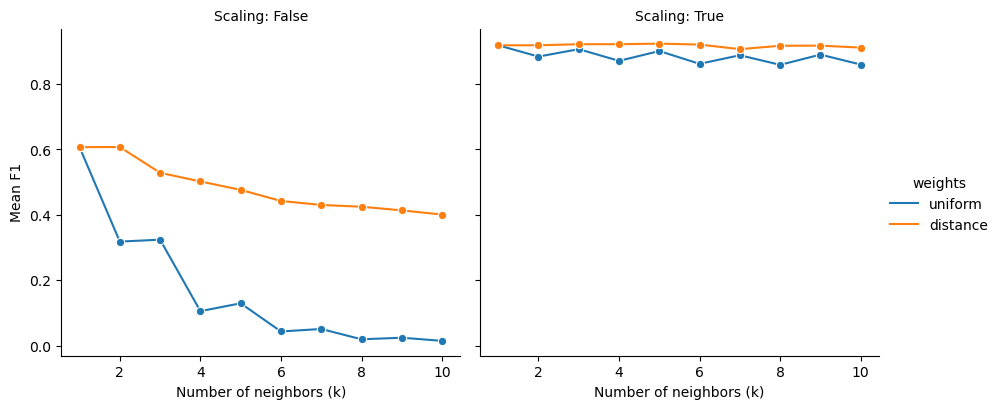

In [26]:
g = sns.relplot(
    data=df_results,
    x="k",
    y="f1_mean",
    hue="weights",
    col="scaled",
    kind="line",
    marker="o",
    height=4,
    aspect=1.1,
    facet_kws={"sharey": True}
)

g.set_axis_labels("Number of neighbors (k)", "Mean F1")
g.set_titles("Scaling: {col_name}")

g.savefig(
    "../assets/figures/knn_cv_f1.en.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Cross-validation of the age-only model

age_cv_scores = cross_val_score(
    DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    X_train[["age"]],
    y_train,
    cv=cv,
    scoring="f1"
)

print(
    f"Decision tree — Mean F1: "
    f"{age_cv_scores.mean():.4f}"
)
print(
    f"Standard deviation: {age_cv_scores.std():.4f}"
)

print(
    f"Best kNN — Mean F1: "
    f"{df_results['f1_mean'].max():.4f}"
)

Decision tree — Mean F1: 0.9718
Standard deviation: 0.0097
Best kNN — Mean F1: 0.9234


### 4.5 Evaluation on the Test Set

In [28]:
best = df_results.sort_values(
    ["f1_mean", "f1_std"],
    ascending=[False, True]
).iloc[0]

print("Best configuration:")
display(best)

best_model = Pipeline([
    (
        "scaler",
        sklearn.preprocessing.MaxAbsScaler()
        if bool(best["scaled"]) else "passthrough"
    ),
    (
        "knn",
        sklearn.neighbors.KNeighborsClassifier(
            n_neighbors=int(best["k"]),
            weights=best["weights"]
        )
    )
])

best_model.fit(X_train, y_train)

Best configuration:


scaled         True
weights    distance
k                 5
f1_mean    0.923362
f1_std     0.029386
Name: 34, dtype: object

Pipeline(steps=[('scaler', MaxAbsScaler()),
                ('knn', KNeighborsClassifier(weights='distance'))])

Selected kNN classifier
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1331
           1       0.98      0.90      0.94       169

    accuracy                           0.99      1500
   macro avg       0.98      0.95      0.97      1500
weighted avg       0.99      0.99      0.99      1500



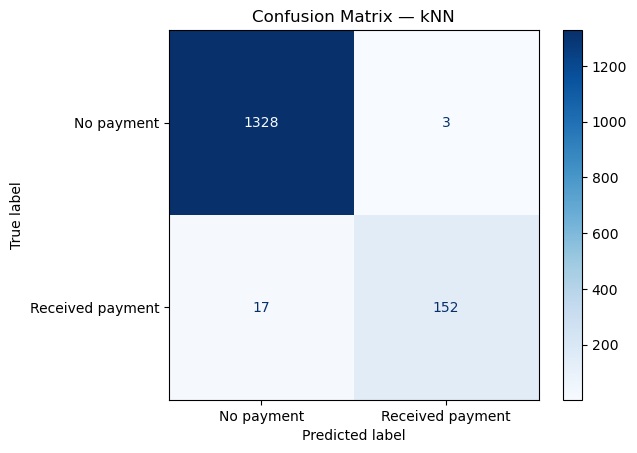

In [29]:
# Final evaluation of the selected kNN model
y_pred = best_model.predict(X_test)

print("Selected kNN classifier")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

cm_knn = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No payment", "Received payment"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — kNN")

disp.figure_.savefig(
    "../assets/figures/knn_confusion_matrix.en.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [30]:
age_baseline = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

age_baseline.fit(
    X_train[["age"]],
    y_train
)

age_pred = age_baseline.predict(
    X_test[["age"]]
)

print(classification_report(y_test, age_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1331
           1       0.92      1.00      0.96       169

    accuracy                           0.99      1500
   macro avg       0.96      0.99      0.98      1500
weighted avg       0.99      0.99      0.99      1500



In [31]:
# Evaluation of baseline models

def rnd_model_predict(p, size, seed=42):
    rng = np.random.default_rng(seed)
    return rng.binomial(n=1, p=p, size=size)


baseline_probabilities = {
    "Always negative": 0.0,
    "Training prevalence": float(y_train.mean()),
    "Random 50/50": 0.5,
    "Always positive": 1.0
}

baseline_results = []

for name, p in baseline_probabilities.items():
    predictions = rnd_model_predict(
        p=p,
        size=len(y_test)
    )

    baseline_results.append({
        "Model": name,
        "F1": sklearn.metrics.f1_score(
            y_test, predictions, zero_division=0
        ),
        "Precision": sklearn.metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": sklearn.metrics.recall_score(
            y_test, predictions, zero_division=0
        )
    })

df_baselines = pd.DataFrame(baseline_results)

display(df_baselines.round(4))

,Model,F1,Precision,Recall
0,Always negative,0.0000,0.0000,0.0000
1,Training prevalence,0.1101,0.1080,0.1124
2,Random 50/50,0.1690,0.1038,0.4556
3,Always positive,0.2025,0.1127,1.0000


In [32]:
model_results = []

for name, predictions in [
    ("Selected kNN", y_pred),
    ("Decision tree (age only)", age_pred)
]:
    model_results.append({
        "Model": name,
        "F1": sklearn.metrics.f1_score(y_test, predictions),
        "Precision": sklearn.metrics.precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": sklearn.metrics.recall_score(
            y_test, predictions, zero_division=0
        )
    })

df_comparison = pd.concat(
    [pd.DataFrame(model_results), df_baselines],
    ignore_index=True
)

df_comparison = df_comparison.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(df_comparison.round(4))

,Model,F1,Precision,Recall
0,Decision tree (age only),0.9602,0.9235,1.0000
1,Selected kNN,0.9383,0.9806,0.8994
2,Always positive,0.2025,0.1127,1.0000
3,Random 50/50,0.1690,0.1038,0.4556
4,Training prevalence,0.1101,0.1080,0.1124
5,Always negative,0.0000,0.0000,0.0000


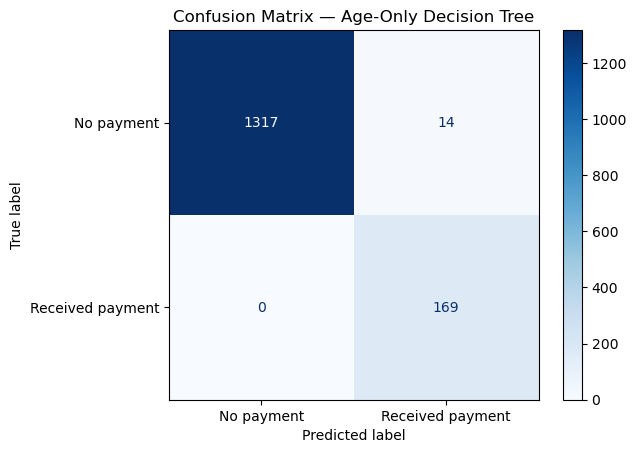

In [33]:
cm_age = confusion_matrix(y_test, age_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_age,
    display_labels=["No payment", "Received payment"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Age-Only Decision Tree")

disp.figure_.savefig(
    "../assets/figures/age_only_confusion_matrix.en.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### 4.6 Interpretation and Discussion of Results

#### Baseline Model Performance

The baselines demonstrated the limitations of simple classification strategies on a dataset with substantial class imbalance.

The always-negative classifier achieved an F1-score of zero because it identified none of the customers with a positive payment history, even though they represent approximately 11.3% of the records.

Among the random and constant baselines, always predicting the positive class yielded the highest F1-score (0.203). However, its precision was just 0.113, because every customer was classified as positive, creating many false positives.

These results reinforce the importance of using evaluation metrics appropriate to the problem instead of relying on accuracy alone.

#### Effects of Scaling and Hyperparameters

Cross-validation showed that feature scaling had a substantial impact on kNN performance.

The best unscaled model achieved a mean F1-score of approximately 0.607, whereas the best scaled configuration reached 0.923.

This agrees with the customer-similarity analysis: without scaling, income disproportionately influences distances because of its numerical magnitude.

The best configuration used five neighbors, `MaxAbsScaler`, and distance-based weighting (`weights="distance"`).

Performance varied with the number of neighbors and the weighting scheme. Scaled configurations with distance-based weighting generally achieved high scores, although the differences between some configurations were relatively small.

The results therefore do not establish that one particular number of neighbors or weighting scheme is universally superior. Rather, they demonstrate why hyperparameter selection should reflect the data's characteristics.

#### kNN Test-Set Evaluation

After selecting hyperparameters through cross-validation, the kNN model was fitted on the full training set and evaluated on the reserved test set.

For the positive class, the classifier achieved an F1-score of approximately 0.94, with precision of 0.98 and recall of 0.90.

Of the 169 customers with a positive payment history, 152 were classified correctly. The model missed 17 positive customers and incorrectly classified three negative customers as positive.

These results demonstrate substantially better predictive performance than the random and constant baseline models.

#### Comparison with the Age-Only Model

Cross-validation also favored the age-only model, which achieved a mean F1-score of 0.9718 (standard deviation 0.0097), compared with 0.9234 (standard deviation 0.0294) for the best kNN configuration.

These results reinforce the finding that age captures much of the predictive signal in this dataset. They do not, however, establish that the same relationship would hold in other populations or periods.

The depth-one decision tree, using only age, achieved an F1-score of approximately 0.96 on the test set, with precision of 0.92 and recall of 1.00.

This finding is particularly relevant: a single feature captured much of the class separation in this dataset.

Compared with kNN, the decision tree achieved higher recall for the positive class but lower precision. This highlights a meaningful difference in the types of errors the models produce.

Choosing between the classifiers would depend on the practical consequences of false positives and false negatives for the insurer, as well as simplicity, interpretability, and generalization.

The observed test-set difference is not, by itself, sufficient to conclude that the decision tree will outperform kNN in other samples or populations.

#### Limitations and Business Implications

The strong association between age and payment history warrants particular attention. The exploratory analysis revealed a sharp transition in payment incidence across ages, suggesting that this dataset's structure may favor age-based models.

Further investigation would be needed to determine whether this reflects a generalizable pattern or a particularity of the sample.

Moreover, the models classify historical records based on payments received during the previous five years. The results do not, on their own, establish the ability to predict future payments.

Operational deployment would require validation on data representative of other populations and periods, along with an assessment of potential impacts of decisions based on policyholders' personal characteristics.

The age-only model was introduced in response to patterns identified during exploratory analysis of the entire dataset. Consequently, this comparison should be understood as an additional exploratory investigation rather than an evaluation completely independent of feature selection.

**Conclusion:** The experiments show that supervised models can identify patterns associated with historical insurance payments with high performance. Scaling proved essential for kNN, while the decision-tree comparison demonstrated that a simpler approach can achieve competitive or better performance, depending on the problem's characteristics and the evaluation metrics prioritized.

## 5. Estimating the Number of Insurance Benefit Payments — Linear Regression

### 5.1 Objective and Methodology

The previous stage examined whether customers could be classified according to the occurrence of insurance benefit payments. The goal now is to estimate **the number of payments received by each policyholder over the preceding five years**.

Unlike binary classification, which considers only whether payments occurred, this experiment uses the original `insurance_benefits` variable, representing the number of recorded payments.

To do this, we will develop our own linear regression implementation using NumPy matrix operations.

The experiment addresses three questions:

1. How well does linear regression estimate the number of insurance benefit payments?
2. Does it outperform a simple strategy based on the mean number of payments?
3. Does feature scaling affect model predictions or predictive performance?

The dataset will be split into training (70%) and test (30%) sets. The same observations will be used to compare models trained on original and scaled features.

We will use two evaluation metrics: **root mean squared error (RMSE)** and the **coefficient of determination (R²)**.

The purpose is not necessarily to find the best possible regression algorithm, but to understand its mathematical operation and investigate the effect of feature scaling on its predictions.

The results will also form the basis for the following experiment, which examines whether predictions are preserved after a matrix transformation of the data.

### 5.2 Mathematical Formulation

Linear regression represents the target variable as a linear combination of the available features.

Let:

- $X$: feature matrix, with one row per observation and one column per feature;
- $y$: vector of observed target values;
- $w$: vector of model coefficients;
- $\hat{y}$: vector of predicted values.

To include an intercept, we add a column of ones to the feature matrix, obtaining $X_b$.

The predictions can then be expressed as:

$$
\hat{y}=X_bw
$$

Training aims to find the coefficients that minimize the sum of squared residuals:

$$
\hat{w}=\underset{w}{\arg\min}\ \|X_bw-y\|_2^2
$$

When $X_b^TX_b$ is invertible, the analytical solution can be expressed using the normal equation:

$$
\hat{w}=(X_b^TX_b)^{-1}X_b^Ty
$$

However, explicitly calculating this inverse can cause numerical stability problems, particularly with highly correlated features or large differences in scale.

For this reason, the implementation uses `np.linalg.lstsq()`, which solves the least-squares problem in a more numerically stable way without explicitly inverting the matrix.

After fitting the model, the estimated coefficients are used to predict values for the test set.

Because the model uses a linear combination of features, scaling may change the coefficient values without substantially changing the predictions when the transformation preserves the information and the least-squares solution remains equivalent.

In [34]:
class MyLinearRegression:
    """
    Ordinary least-squares linear regression implemented
    with NumPy.
    """

    def __init__(self):
        self.weights = None

    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X must be a two-dimensional matrix.")

        return np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

    def fit(self, X, y):
        X_b = self._add_intercept(X)
        y = np.asarray(y, dtype=float)

        self.weights = np.linalg.lstsq(
            X_b,
            y,
            rcond=None
        )[0]

        return self

    def predict(self, X):
        if self.weights is None:
            raise ValueError("The model has not been fitted yet.")

        X_b = self._add_intercept(X)

        return X_b @ self.weights

In [35]:
def eval_regressor(y_true, y_pred, model_name):
    rmse = np.sqrt(
        sklearn.metrics.mean_squared_error(y_true, y_pred)
    )

    r2 = sklearn.metrics.r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "RMSE": rmse,
        "R²": r2
    }

In [36]:
# Prepare data for regression

X_reg = df[feature_names].copy()
y_reg = df["insurance_benefits"].copy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=12345
)

# Regression using original features

model_reg_original = MyLinearRegression()
model_reg_original.fit(X_train_reg, y_train_reg)

y_pred_reg_original = model_reg_original.predict(X_test_reg)

print("Original model coefficients:")
print(model_reg_original.weights)

display(pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Linear regression — original features"
    )
]).round(4))

Original model coefficients:
[-9.43539012e-01  1.64272726e-02  3.57495491e-02 -2.60743659e-07
 -1.16902127e-02]


,Model,RMSE,R²
0,Linear regression — original features,0.3436,0.4305


In [37]:
# Fit scaling exclusively on training data

scaler_reg = sklearn.preprocessing.MaxAbsScaler()

X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Regression using scaled features

model_reg_scaled = MyLinearRegression()
model_reg_scaled.fit(X_train_reg_scaled, y_train_reg)

y_pred_reg_scaled = model_reg_scaled.predict(X_test_reg_scaled)

# Baseline: always predict the training-set mean

y_pred_reg_baseline = np.full(
    len(y_test_reg),
    y_train_reg.mean()
)

# Compare model performance

regression_results = pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Linear regression — original"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_scaled,
        "Linear regression — scaled"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_baseline,
        "Baseline — mean"
    )
])

display(regression_results.round(6))

# Compare prediction vectors directly

max_difference = np.max(
    np.abs(y_pred_reg_original - y_pred_reg_scaled)
)

print(f"Maximum absolute difference: {max_difference:.12f}")

print(
    "Predictions numerically equivalent:",
    np.allclose(
        y_pred_reg_original,
        y_pred_reg_scaled,
        rtol=1e-6,
        atol=1e-8
    )
)

coefficient_comparison = pd.DataFrame({
    "Feature": ["Intercept"] + feature_names,
    "Original": model_reg_original.weights,
    "Scaled": model_reg_scaled.weights
})

display(coefficient_comparison)

,Model,RMSE,R²
0,Linear regression — original,0.343557,0.430528
1,Linear regression — scaled,0.343557,0.430528
2,Baseline — mean,0.455298,-0.000158


Maximum absolute difference: 0.000000000000
Predictions numerically equivalent: True


,Feature,Original,Scaled
0,Intercept,-9.435390e-01,-0.943539
1,gender,1.642727e-02,0.016427
2,age,3.574955e-02,2.323721
3,income,-2.607437e-07,-0.020599
4,family_members,-1.169021e-02,-0.070141


### 5.3 Interpretation and Discussion of Results

Comparing the linear regression models allows us to investigate the effect of feature scaling on estimating the number of insurance benefit payments.

The experiments using original and scaled features produced numerically equivalent results, indicating that scaling preserved the model's predictions within floating-point precision.

Although the estimated coefficients differed, the changes compensated for the rescaling of the features. This occurs because unregularized least-squares linear regression is invariant to invertible linear transformations of the features when those transformations are applied consistently.

Directly comparing the prediction vectors verifies this equivalence without relying exclusively on rounded RMSE and R² values.

Linear regression achieved an RMSE of 0.3436 and R² of 0.4305 on the test set, outperforming the mean-prediction baseline, which achieved an RMSE of 0.4553 and an R² of approximately zero.

This represents an approximately **24.5% reduction in RMSE** compared with the baseline.

Scaling did not change predictive performance within numerical precision, although it altered the coefficients associated with the features.

**Limitations:** Linear regression produces continuous predictions even though the target represents a count of payments. Consequently, the model can produce fractional or even negative values, which do not directly correspond to possible payment counts.

In addition, the relationship between policyholder characteristics and the number of payments may not be fully linear. The results should therefore be interpreted as a demonstration of the properties and limitations of linear regression, rather than evidence that it is necessarily the most suitable model for operational use.

The experiment also lays the groundwork for an additional question: if scaling can preserve linear regression predictions, could a broader matrix transformation achieve the same result?

## 6. Data Obfuscation Through Matrix Transformations

### 6.1 Objective and Methodology

The insurance company Protect Your Tomorrow (Proteja Seu Amanhã) wants to investigate whether it can make customers' personal information harder to interpret directly without compromising its regression models' performance.

We will explore an obfuscation method based on multiplying the feature matrix by an invertible square matrix.

Unlike the scaling performed earlier, this transformation linearly combines the original features, producing new variables whose values cannot be interpreted directly as age, income, sex, or number of family members.

The experiment addresses three questions:

1. Can the data be transformed so that the original features are no longer directly recognizable?
2. Can the original values be recovered using the inverse matrix?
3. Does the transformation preserve linear regression predictions and performance?

We will proceed through three stages: transforming and recovering the data, mathematically demonstrating prediction invariance, and validating it experimentally using the custom linear regression model from the previous section.

**Limitation:** The method examined here is a form of mathematical obfuscation, not encryption. The transformation is reversible and does not, by itself, provide privacy or security guarantees against attempts to recover the original information.

### 6.2 Data Transformation and Recovery

Let $X$ be the feature matrix and $P$ an invertible square matrix whose size equals the number of features.

The transformation is defined as:

$$
X' = XP
$$

Each column of $X'$ is a linear combination of the original features.

Because $P$ is invertible, the original data can be recovered through the inverse transformation:

$$
X = X'P^{-1}
$$

In [38]:
# Reproducible transformation matrix
rng_obf = np.random.default_rng(42)

n_features = X_train_reg.shape[1]

# Select an invertible, reasonably well-conditioned
# matrix to limit numerical errors.
while True:
    P = rng_obf.normal(size=(n_features, n_features))

    if (
        np.linalg.matrix_rank(P) == n_features
        and np.linalg.cond(P) < 100
    ):
        break

P_inv = np.linalg.inv(P)

print("Shape of matrix P:", P.shape)
print("Rank of matrix P:", np.linalg.matrix_rank(P))
print("Condition number:", np.linalg.cond(P))

# Apply transformation to the same dataset
# used in the previous regression experiment.
X_train_obf = X_train_reg.to_numpy(dtype=float) @ P
X_test_obf = X_test_reg.to_numpy(dtype=float) @ P

# Recover test-set data
X_test_recovered = X_test_obf @ P_inv

print(
    "Recovered data equivalent to original:",
    np.allclose(
        X_test_reg.to_numpy(dtype=float),
        X_test_recovered
    )
)

print(
    "Maximum absolute recovery difference:",
    np.max(
        np.abs(
            X_test_reg.to_numpy(dtype=float)
            - X_test_recovered
        )
    )
)

Shape of matrix P: (4, 4)
Rank of matrix P: 4
Condition number: 26.88453024045781
Recovered data equivalent to original: True
Maximum absolute recovery difference: 7.275957614183426e-11


In [39]:
print("Original data:")
display(X_test_reg.head())

print("Obfuscated data:")
display(
    pd.DataFrame(
        X_test_obf[:5],
        columns=[f"z_{i+1}" for i in range(n_features)]
    ).round(3)
)

print("Recovered data:")
display(
    pd.DataFrame(
        X_test_recovered[:5],
        columns=feature_names
    ).round(3)
)

Original data:


,gender,age,income,family_members
3183,0,33,39000.0,4
1071,0,50,43100.0,2
2640,1,39,42100.0,0
2282,0,20,34800.0,0
1595,0,41,40000.0,4


Obfuscated data:


,z_1,z_2,z_3,z_4
0,-719.365,-33307.176,34302.610,30320.012
1,-821.550,-36829.048,37909.380,33505.302
2,-783.114,-35964.974,37028.391,32733.648
3,-623.701,-29711.972,30605.606,27060.835
4,-751.775,-34170.637,35183.030,31095.274


Recovered data:


,gender,age,income,family_members
0,-0.0,33.0,39000.0,4.0
1,-0.0,50.0,43100.0,2.0
2,1.0,39.0,42100.0,-0.0
3,-0.0,20.0,34800.0,-0.0
4,-0.0,41.0,40000.0,4.0


### 6.3 Mathematical Proof of Prediction Invariance

The objective of this section is to demonstrate why an invertible linear transformation of the features can preserve predictions from ordinary least-squares linear regression.

#### Transformation of the Coefficients

Let $X$ denote the original feature matrix and $P$ an invertible square matrix.

The data transformation is:

$$
X' = XP
$$

To account for the intercept used in our implementation, define the augmented feature matrix:

$$
X_b = [\mathbf{1}\;\;X]
$$

We can represent the full transformation using a block matrix:

$$
T =
\begin{bmatrix}
1 & 0\\
0 & P
\end{bmatrix}
$$

Then the transformed feature matrix, including the intercept, becomes:

$$
X'_b = X_bT
$$

In ordinary least-squares linear regression, when the augmented feature matrix has full column rank, the coefficients can be obtained using the normal equation:

$$
w=(X_b^TX_b)^{-1}X_b^Ty
$$

For the transformed data:

$$
w'=[(X_bT)^T(X_bT)]^{-1}(X_bT)^Ty
$$

Using the properties of matrix transposition and inversion of matrix products:

$$
w'=(T^TX_b^TX_bT)^{-1}T^TX_b^Ty
$$

$$
w'=T^{-1}(X_b^TX_b)^{-1}(T^T)^{-1}T^TX_b^Ty
$$

Since $(T^T)^{-1}T^T=I$, we obtain:

$$
\boxed{w'=T^{-1}w}
$$

Thus, the transformed model's coefficients compensate for the transformation applied to the features.

The intercept remains unchanged, while the feature coefficients are transformed by $P^{-1}$.

#### Invariance of Predictions

Predictions from the original model are:

$$
\hat{y}=X_bw
$$

Predictions using the transformed data and their corresponding coefficients are:

$$
\hat{y}'=X'_bw'
$$

Substituting the relationships derived above:

$$
\hat{y}'=(X_bT)(T^{-1}w)
$$

By associativity of matrix multiplication:

$$
\hat{y}'=X_b(TT^{-1})w
$$

Since $TT^{-1}=I$:

$$
\boxed{\hat{y}'=X_bw=\hat{y}}
$$

We have therefore demonstrated that an invertible feature transformation can preserve ordinary least-squares linear regression predictions.

Because RMSE and R² depend on observed and predicted values, identical predictions yield identical values for these metrics.

The coefficient relationship above assumes a unique least-squares solution. Even when coefficients are non-unique, invertible transformations preserve the space of possible predictions, although individual coefficients may not satisfy the same relationship for every numerical implementation.

In practice, small differences can arise from floating-point precision.

### 6.4 Experimental Validation

To verify the demonstrated property computationally, we will compare two linear regression models:

- A model trained on the original features.
- A model trained on the same observations after the matrix transformation.

Both models use `MyLinearRegression`, developed in the preceding section, and are evaluated using the same target values and training/test observations.

We will compare RMSE, R², and the differences between the prediction vectors.

We will also verify whether the estimated coefficients satisfy the mathematical relationship derived above.

In [40]:
# Model trained with obfuscated features
model_reg_obf = MyLinearRegression()

model_reg_obf.fit(
    X_train_obf,
    y_train_reg
)

y_pred_reg_obf = model_reg_obf.predict(X_test_obf)

# Compare performance
obfuscation_results = pd.DataFrame([
    eval_regressor(
        y_test_reg,
        y_pred_reg_original,
        "Regression — original features"
    ),
    eval_regressor(
        y_test_reg,
        y_pred_reg_obf,
        "Regression — obfuscated features"
    )
])

display(obfuscation_results.round(8))

# Compare prediction vectors directly
prediction_difference = np.abs(
    y_pred_reg_original - y_pred_reg_obf
)

print(
    "Maximum absolute difference:",
    f"{prediction_difference.max():.12e}"
)

print(
    "Predictions equivalent:",
    np.allclose(
        y_pred_reg_original,
        y_pred_reg_obf,
        rtol=1e-7,
        atol=1e-8
    )
)

# Mathematical relationship between coefficients
expected_weights = np.concatenate([
    [model_reg_original.weights[0]],
    np.linalg.solve(
        P,
        model_reg_original.weights[1:]
    )
])

print(
    "Coefficients consistent with transformation:",
    np.allclose(
        expected_weights,
        model_reg_obf.weights,
        rtol=1e-6,
        atol=1e-8
    )
)

,Model,RMSE,R²
0,Regression — original features,0.343557,0.430528
1,Regression — obfuscated features,0.343557,0.430528


Maximum absolute difference: 1.604605337491e-12
Predictions equivalent: True
Coefficients consistent with transformation: True


### 6.5 Interpretation, Limitations, and Implications

The experiment investigates whether multiplying the policyholders' personal characteristics by an invertible matrix can change how the data are represented while preserving the information required for linear regression.

The transformation produces new features that combine the original values and no longer directly represent variables such as age or income.

Nevertheless, the transformation is reversible: if the matrix is known, the original data can be recovered using its inverse, subject to small floating-point differences.

The mathematical proof establishes why an invertible linear transformation, applied consistently to training and test features, can preserve predictions from unregularized ordinary least-squares linear regression.

The experimental validation checks this property in the dataset by directly comparing predictions, performance metrics, and model coefficients.

**Limitations:** Although this technique makes the transformed values harder to interpret directly, it does not guarantee anonymity or confidentiality. The transformation matrix and its inverse provide the means to recover the data. Obfuscation is not a substitute for encryption, access controls, or formal privacy-preserving methods.

The demonstrated invariance is also specific to the invertible transformations considered here and to ordinary least-squares linear regression. It should not automatically be generalized to other algorithms, particularly distance-based models or those that penalize model coefficients.

The experimental validation confirmed numerical equivalence of the predictions. Both the model trained on original features and the one trained on obfuscated features achieved an **RMSE of 0.343557** and **R² of 0.430528**.

The maximum absolute difference between prediction vectors was approximately **1.60 × 10⁻¹²**, and `np.allclose()` confirmed their numerical equivalence. The fitted coefficients also satisfied the expected mathematical transformation relationship.

The original data were successfully recovered using the inverse matrix, with a maximum absolute difference of approximately **7.28 × 10⁻¹¹**, attributable to floating-point precision.

The results therefore confirm that the invertible matrix transformation preserved linear regression performance in this experiment. However, predictive equivalence does not mean the data are protected against unauthorized recovery, because the transformation is reversible.

## 7. Conclusions

This project investigated how data analysis, machine learning, and linear algebra can address four problems in the insurance domain: identifying similar customers, classifying customers by their payment histories, estimating the number of payments, and obfuscating personal information.

The experiments demonstrated the potential of these techniques to extract useful information while highlighting the importance of preprocessing, methodological choices, and critical evaluation of results.

### Key Findings

**1. Identifying Similar Customers**

Nearest-neighbor search demonstrated that policyholders with similar characteristics can be identified using distance metrics.

Scaling was particularly important because differences in numerical magnitude caused income to dominate distance calculations in the original data.

Euclidean and Manhattan distances produced similar results. For a random sample of 100 customers, the average overlap between the ten nearest neighbors identified by each metric was **88.6%**, using scaled features.

These results establish the technical feasibility of developing a similar-customer search mechanism, although the most useful definition of similarity would depend on the application’s specific business objectives.

**2. Classification by Payment History**

The classification models substantially outperformed the constant and random baselines.

The best kNN model, selected through cross-validation, used five neighbors, `MaxAbsScaler`, and distance-based weighting. Its mean cross-validation F1-score was **0.9234**, and it achieved **0.9383** on the test set.

However, a depth-one decision tree using only customer age performed even better: a mean cross-validation F1-score of **0.9718** and a test-set F1-score of **0.9602**.

This result was particularly informative because it demonstrated that a single feature can capture much of the class separation in this dataset.

The comparison illustrates that more complex models, or models using more features, do not necessarily provide better performance. Simplicity and interpretability should also inform the selection of an analytical solution.

**3. Estimating the Number of Payments with Linear Regression**

Implementing ordinary least-squares linear regression from scratch made it possible to investigate both predictive performance and the algorithm's mathematical properties.

The model achieved an **RMSE of 0.3436 and R² of 0.4305** on the test set, outperforming the mean-prediction baseline, whose RMSE was 0.4553. This represents an approximately **24.5% reduction in RMSE**.

Although the model explained some of the observed variation, a substantial portion remained unexplained by the fitted linear relationship.

The experiment also confirmed that feature scaling preserved predictions numerically despite changing the coefficients. This provided a foundation for investigating matrix transformations in the following section.

**4. Data Obfuscation and Preservation of Predictions**

Transforming the features with an invertible square matrix demonstrated that their representation can be changed without degrading predictions from ordinary least-squares linear regression.

The mathematical proof established the relationship between the coefficients of the original and transformed models, while the computational validation confirmed their numerical equivalence.

Both models achieved the same evaluation results, with **RMSE of 0.343557 and R² of 0.430528**. The maximum absolute difference between predictions was approximately **1.60 × 10⁻¹²**, consistent with floating-point limitations.

The experiment also demonstrated that the original data can be recovered using the inverse matrix.

Thus, the transformation preserved the information needed for linear regression, but it is not encryption and does not guarantee confidentiality. Its reversibility is an important limitation for any application involving personal information.

### Limitations and Considerations for Practical Use

Despite the positive results, several limitations must be considered:

- **Data representativeness:** The unusually strong association between age and receipt of insurance benefit payments may reflect characteristics specific to this dataset. Generalization to other populations or periods has not been established.
- **Predictive scope:** The models were evaluated using historical payment records. These results do not, by themselves, demonstrate the ability to predict future payments in operational conditions.
- **Model suitability:** Linear regression can produce fractional or negative estimates for a count target, suggesting that other approaches should be considered for practical deployment.
- **Privacy and responsible data use:** Matrix obfuscation does not replace formal safeguards for personal information. Real-world insurance applications would also require assessments of representativeness, fairness, and potential discriminatory impacts.

### Final Remarks

The four experiments demonstrated how different techniques can address related problems using the same dataset, each with its own goals, assumptions, and limitations.

Three lessons stand out: **the importance of preprocessing for distance-based methods; the value of comparing complex models with simple, interpretable alternatives; and the ability to establish algorithmic properties by combining linear algebra with experimental validation.**

Taken together, this project reinforces that developing data science solutions involves more than achieving strong predictive metrics. It requires understanding the data, justifying methodological choices, validating findings, and critically assessing their applicability to the business problem.